# Phase 1 Preprocessing & Exploratory Data Analysis (EDA)

**Project:** Rainfall-Lag-Aware Crop Yield Forecasting in India Using Explainable Temporal Machine Learning

**Objectives:**
1. Execute leakage-safe preprocessing with complete audit accounting.
2. Establish stable geographic identifiers (`State_DistCode`).
3. Explicitly define feature roles (`FEATURE | UNIT | ROLE | INCLUDED?`).
4. Generate and save publication-grade EDA figures under `results/figures/`.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd()))

from src.preprocessing import preprocess_data
from src.visualization import (
    plot_yield_distribution,
    plot_yield_over_time,
    plot_rainfall_over_time,
    plot_rainfall_vs_yield,
    plot_temperature_vs_yield,
    plot_state_mean_yield,
    plot_district_mean_yield,
    plot_observations_by_year,
    plot_correlation_matrix,
)
print('Preprocessing and visualization tools loaded.')

Preprocessing and visualization tools loaded.


## 1. Execute Preprocessing & Filter Accounting
Every row removal decision is explicitly accounted for.

In [2]:
clean_df, audit_df = preprocess_data(save_processed=True)
print(f'Clean Processed Records: {len(clean_df)}')
audit_df

Clean Processed Records: 10279


,step,reason,rows_removed,remaining_rows
0,Raw Ingestion,Initial raw observations loaded from source CSV,0,10279
1,Deduplication,Exact row duplicate removal,0,10279
2,Target Validation,Removal of non-positive or missing rice yield ...,0,10279
3,Rainfall Validation,Removal of negative or missing aggregate rainf...,0,10279


## 2. Feature Specification Matrix
Explicit documentation of column roles, units, and inclusion decisions.

| FEATURE | UNIT | ROLE | INCLUDED? | RATIONALE |
| :--- | :--- | :--- | :--- | :--- |
| `RICE.YIELD..Kg.per.ha.` | kg/ha | Primary Target | YES (Target) | Standard productivity target unit |
| `IMD_RF` | mm | Numerical Predictor | YES (Predictor) | Aggregate rainfall observation |
| `IMD_Tmax` | °C | Numerical Predictor | YES (Predictor) | Mean maximum seasonal temperature |
| `SD_RF_jun_nov` | mm (std) | Numerical Predictor | YES (Predictor) | Intra-seasonal rainfall variability |
| `State` | categorical | Categorical Predictor | YES (Predictor) | One-hot encoded spatial baseline |
| `RICE.AREA..1000.ha.` | 1000 ha | Descriptive Only | NO (Excluded) | Post-planting / target leakage risk |
| `RICE.PRODUCTION..1000.tons.` | 1000 tons | Descriptive Only | NO (Excluded) | Yield = Prod / Area (direct leakage) |
| `RICE.SHARE.IN.TOTAL..Percent.` | % | Descriptive Only | NO (Excluded) | Contains 758 missing values; post-sowing |
| `FID_1` | integer | Arbitrary Index | NO (Excluded) | GIS database artifact; uninformative |
| `Dist.Code` | integer | Geographic ID | NO (Predictor) | Retained strictly for spatial indexing |
| `Sh_Dist_code` | integer | Shapefile ID | NO (Excluded) | Shapefile code redundant with Dist.Code |
| `Year` | year | Temporal Index | NO (Predictor) | Reserved strictly for chronological partitioning |
| `Crops` | string | Metadata | NO (Excluded) | Invariant constant ('Rice') across all records |
| `AgroClimate` | string | Spatial Metadata | NO (Excluded) | Redundant with State; 168 missing values |

In [3]:
feature_matrix = pd.DataFrame([
    {'FEATURE': 'RICE.YIELD..Kg.per.ha.', 'UNIT': 'kg/ha', 'ROLE': 'Target', 'INCLUDED': 'YES'},
    {'FEATURE': 'IMD_RF', 'UNIT': 'mm', 'ROLE': 'Numerical Predictor', 'INCLUDED': 'YES'},
    {'FEATURE': 'IMD_Tmax', 'UNIT': '°C', 'ROLE': 'Numerical Predictor', 'INCLUDED': 'YES'},
    {'FEATURE': 'SD_RF_jun_nov', 'UNIT': 'mm (std)', 'ROLE': 'Numerical Predictor', 'INCLUDED': 'YES'},
    {'FEATURE': 'State_Clean', 'UNIT': 'category', 'ROLE': 'Spatial Predictor', 'INCLUDED': 'YES (One-Hot)'},
    {'FEATURE': 'RICE.AREA..1000.ha.', 'UNIT': '1000 ha', 'ROLE': 'Descriptive Metadata', 'INCLUDED': 'NO (Leakage)'},
    {'FEATURE': 'RICE.PRODUCTION..1000.tons.', 'UNIT': '1000 tons', 'ROLE': 'Descriptive Metadata', 'INCLUDED': 'NO (Leakage)'},
    {'FEATURE': 'RICE.SHARE.IN.TOTAL..Percent.', 'UNIT': '%', 'ROLE': 'Descriptive Metadata', 'INCLUDED': 'NO (Leakage)'},
    {'FEATURE': 'Dist.Code', 'UNIT': 'id', 'ROLE': 'Spatial Index', 'INCLUDED': 'NO (ID)'},
    {'FEATURE': 'Year', 'UNIT': 'year', 'ROLE': 'Temporal Index', 'INCLUDED': 'NO (Split Key)'},
])
feature_matrix

,FEATURE,UNIT,ROLE,INCLUDED
0,RICE.YIELD..Kg.per.ha.,kg/ha,Target,YES
1,IMD_RF,mm,Numerical Predictor,YES
2,IMD_Tmax,°C,Numerical Predictor,YES
3,SD_RF_jun_nov,mm (std),Numerical Predictor,YES
4,State_Clean,category,Spatial Predictor,YES (One-Hot)
5,RICE.AREA..1000.ha.,1000 ha,Descriptive Metadata,NO (Leakage)
6,RICE.PRODUCTION..1000.tons.,1000 tons,Descriptive Metadata,NO (Leakage)
7,RICE.SHARE.IN.TOTAL..Percent.,%,Descriptive Metadata,NO (Leakage)
8,Dist.Code,id,Spatial Index,NO (ID)
9,Year,year,Temporal Index,NO (Split Key)


## 3. Exploratory Data Analysis (EDA) Figures
Generate and save all 9 required scientific EDA plots under `results/figures/`.

In [4]:
fig_dir = Path('results/figures')
fig_dir.mkdir(parents=True, exist_ok=True)

# 1. Rice Yield Distribution
plot_yield_distribution(clean_df, fig_dir / 'rice_yield_distribution.png')

# 2. Rice Yield Over Time
plot_yield_over_time(clean_df, fig_dir / 'rice_yield_over_time.png')

# 3. Rainfall Over Time
plot_rainfall_over_time(clean_df, fig_dir / 'rainfall_over_time.png')

# 4. Rainfall vs Yield
plot_rainfall_vs_yield(clean_df, fig_dir / 'rainfall_vs_yield.png')

# 5. Temperature vs Yield
plot_temperature_vs_yield(clean_df, fig_dir / 'temperature_vs_yield.png')

# 6. State Mean Yield
plot_state_mean_yield(clean_df, fig_dir / 'state_mean_yield.png')

# 7. District Mean Yield Extreme Cohorts
plot_district_mean_yield(clean_df, fig_dir / 'district_mean_yield.png')

# 8. Observations by Year
plot_observations_by_year(clean_df, fig_dir / 'observations_by_year.png')

# 9. Correlation Matrix
plot_correlation_matrix(clean_df, fig_dir / 'correlation_matrix.png')

print('All 9 EDA figures saved successfully to results/figures/')

C:\Users\sanka\OneDrive\Desktop\SE DA\src\visualization.py:98: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right")


C:\Users\sanka\OneDrive\Desktop\SE DA\src\visualization.py:118: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right")


C:\Users\sanka\OneDrive\Desktop\SE DA\src\visualization.py:128: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_avg, x="RICE.YIELD..Kg.per.ha.", y=state_col, ax=ax, palette="mako")


All 9 EDA figures saved successfully to results/figures/


### Figure Previews
Inspect key figures directly within the notebook.

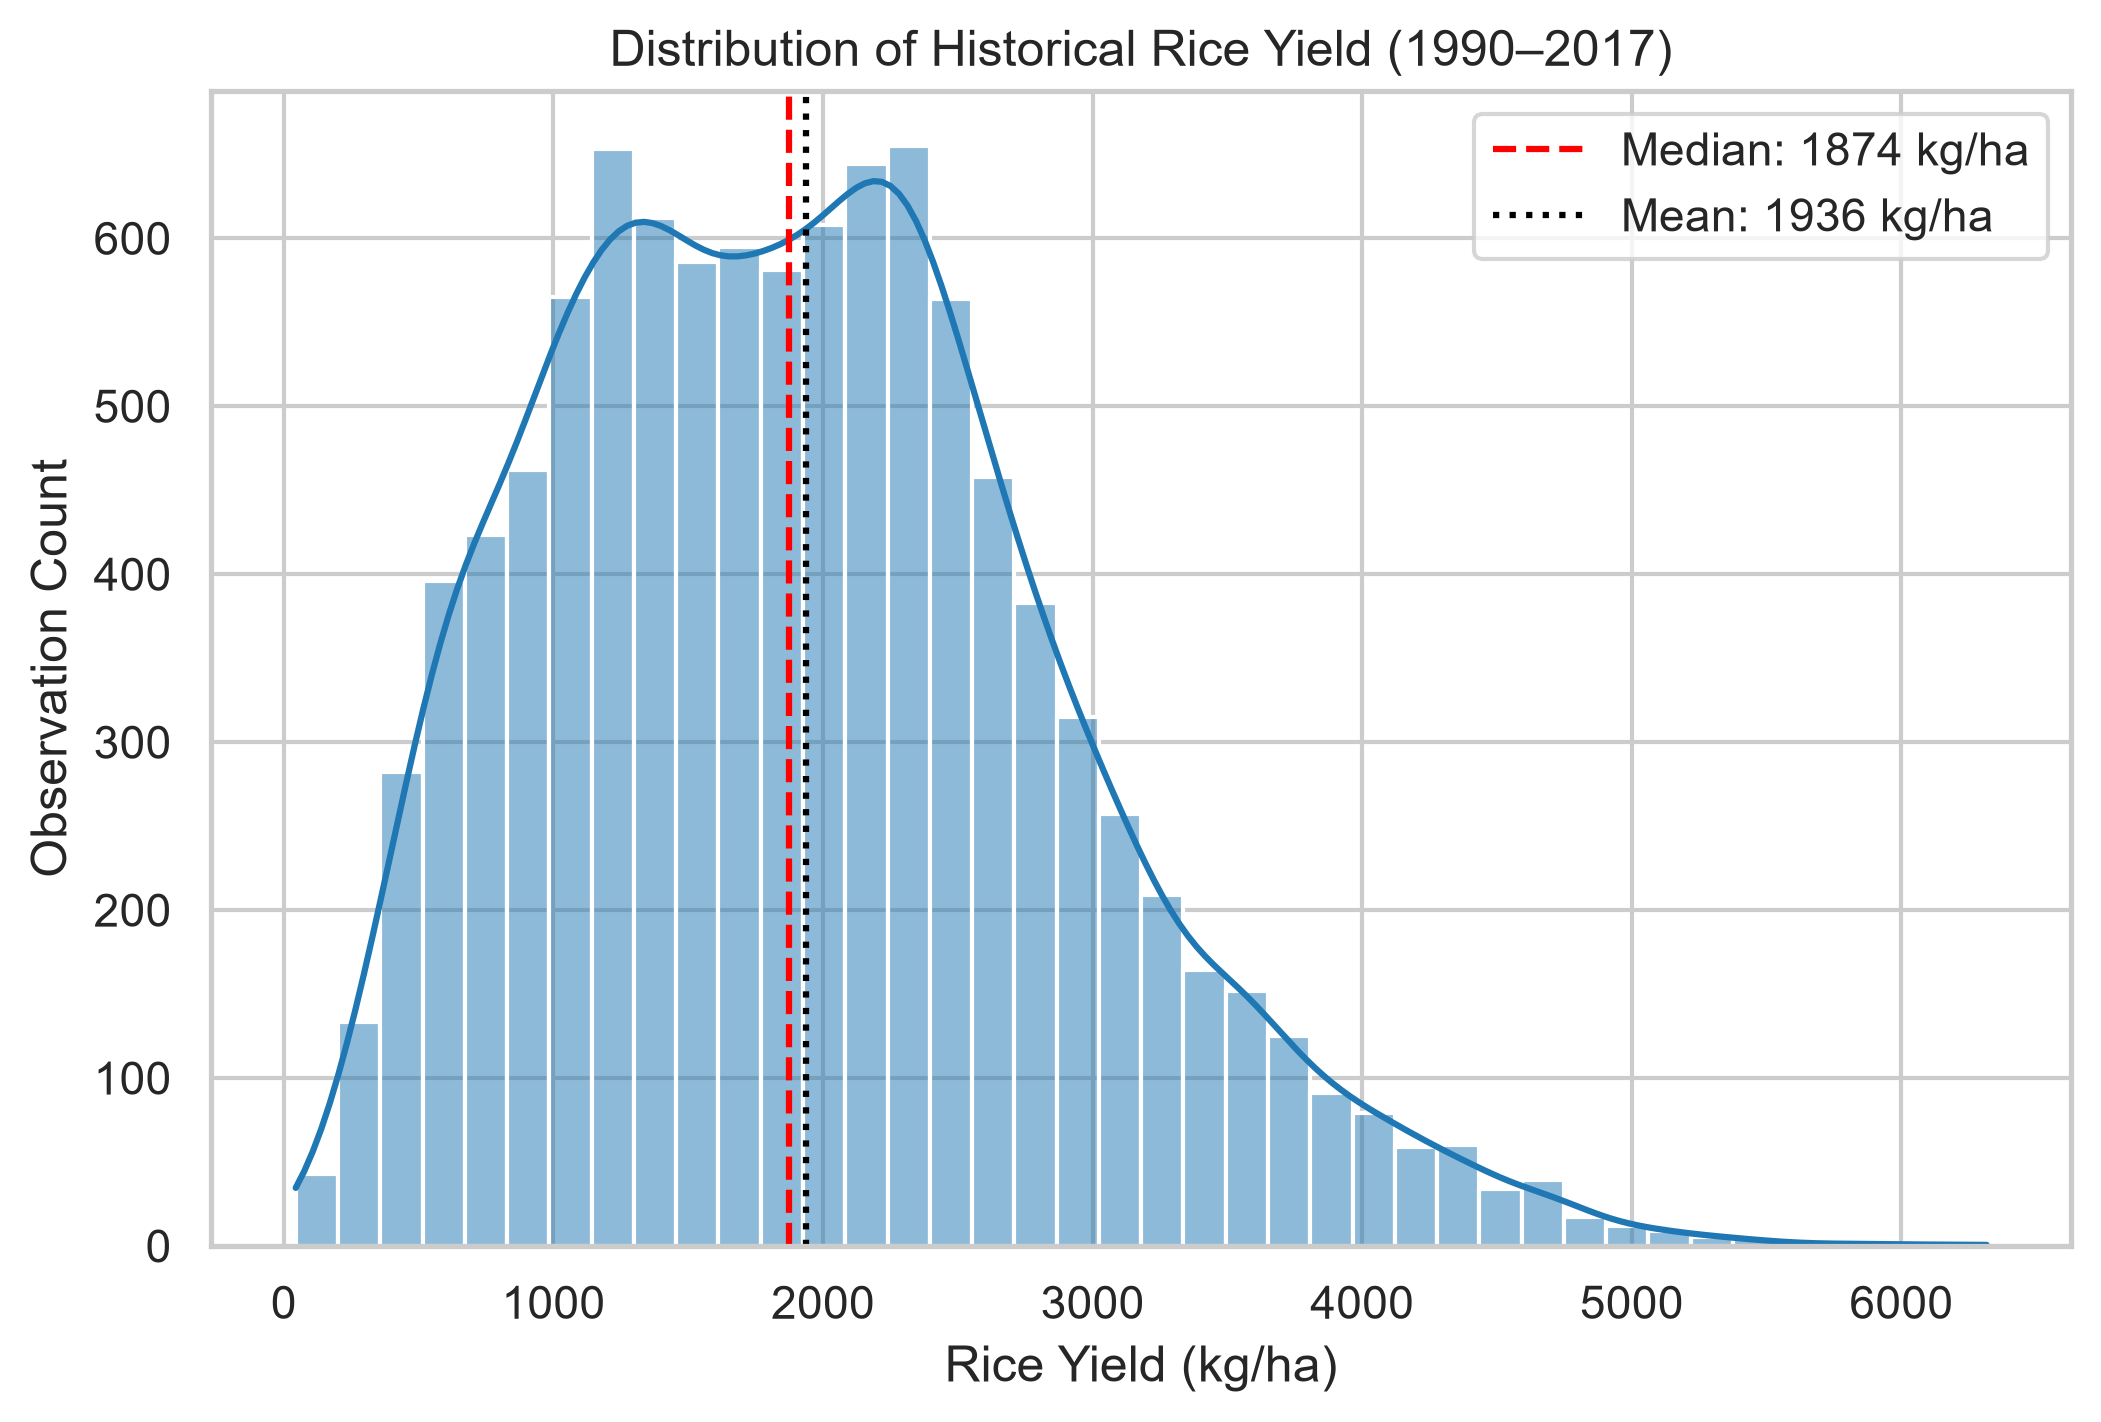

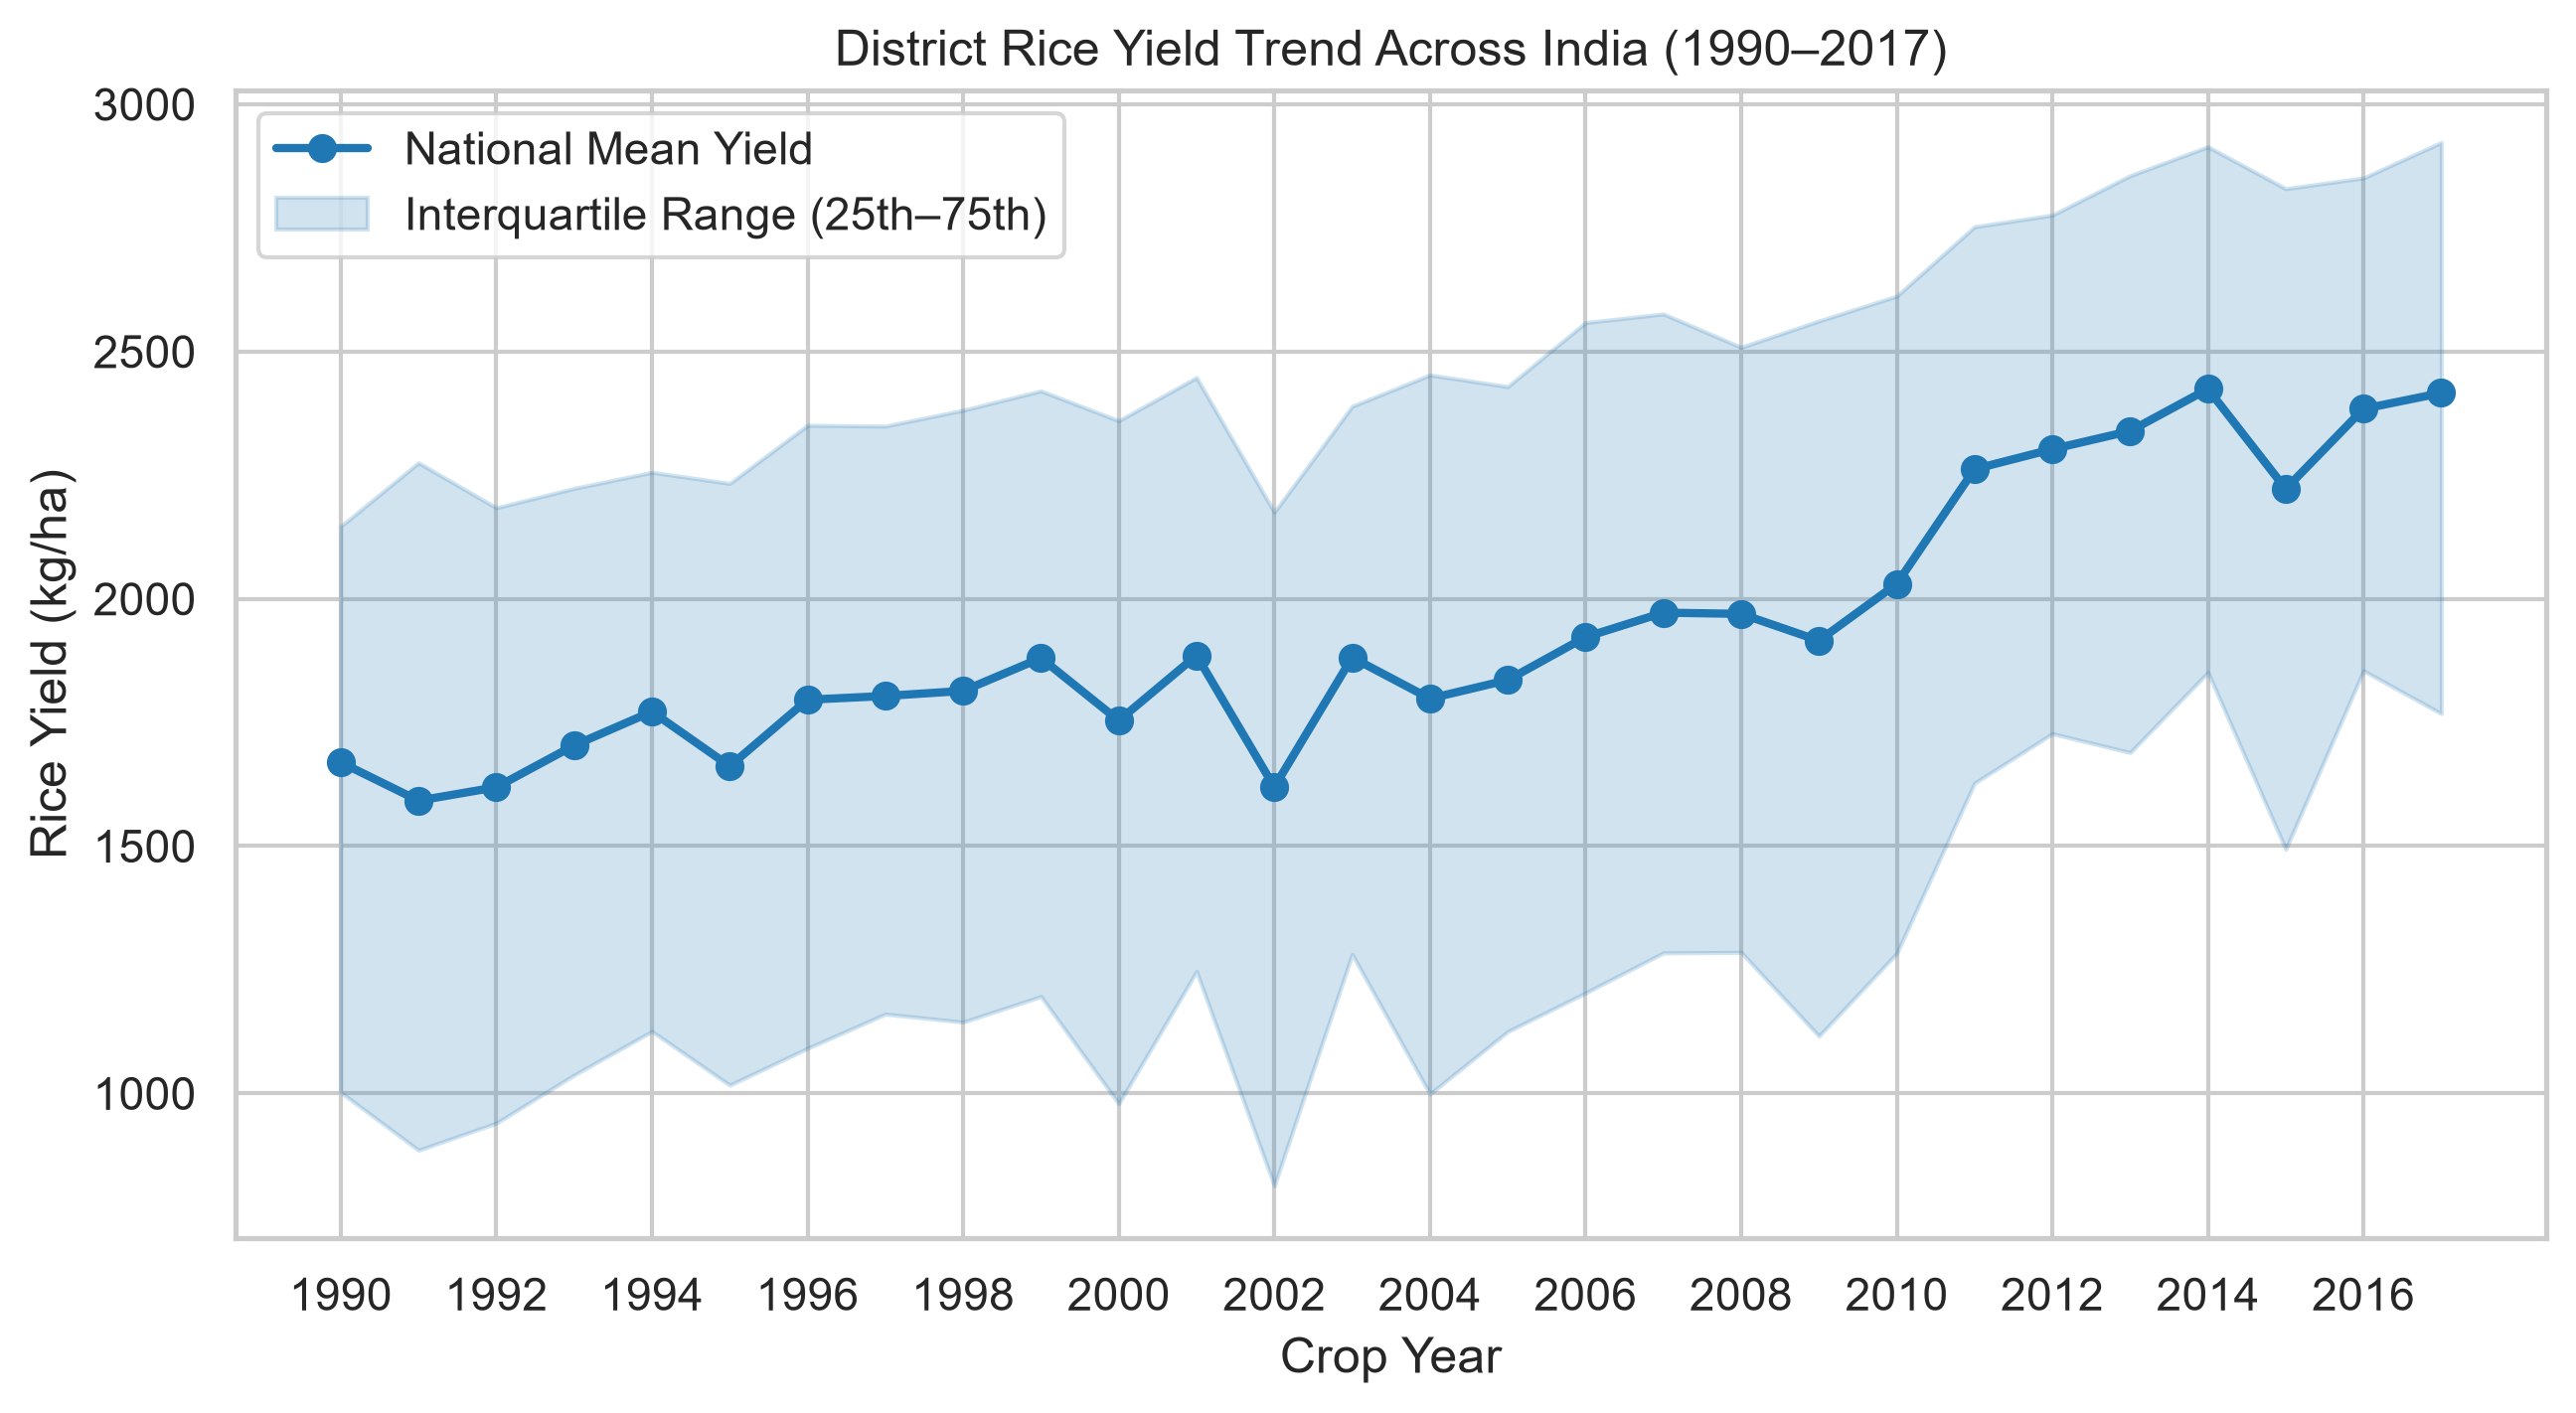

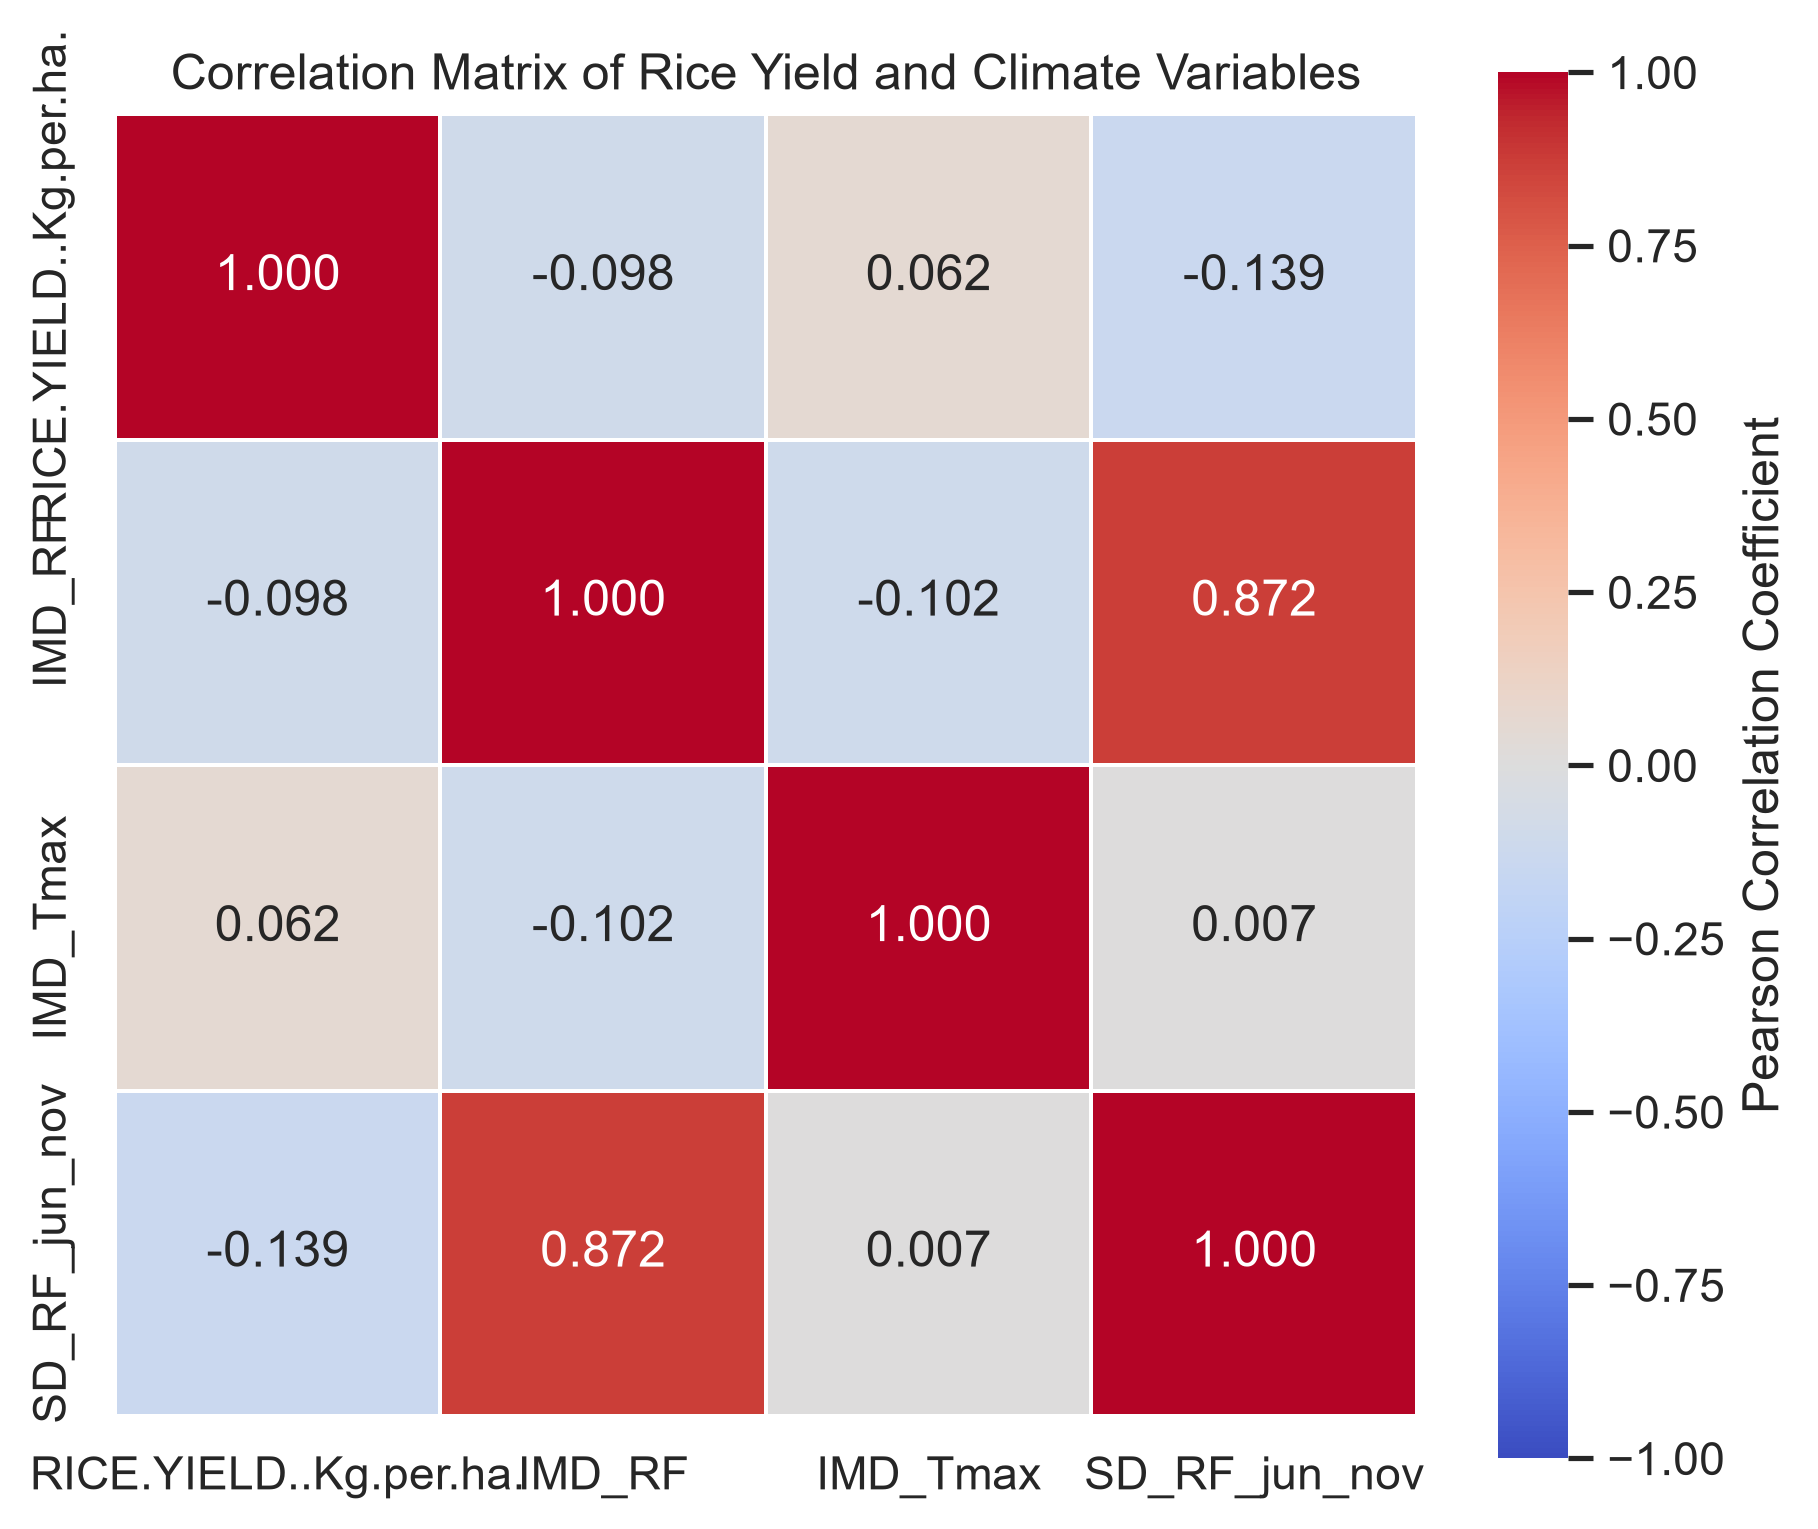

In [5]:
display(Image(filename='results/figures/rice_yield_distribution.png'))
display(Image(filename='results/figures/rice_yield_over_time.png'))
display(Image(filename='results/figures/correlation_matrix.png'))